<style>
.jp-Notebook {max-width:1220px;margin:auto;padding:32px!important}
.jp-RenderedHTMLCommon {font-family:Arial,Helvetica,sans-serif;color:#182B49;line-height:1.6}
.jp-RenderedHTMLCommon h1 {font-size:34px!important;letter-spacing:-.6px;line-height:1.15}
.jp-RenderedHTMLCommon h2 {border-bottom:2px solid #DFE6ED;padding-bottom:8px;margin-top:34px}
.cover {padding:34px 38px;border-left:7px solid #C69214;background:#182B49;color:white;border-radius:4px}
.cover h1 {color:white!important;margin:8px 0!important}.eyebrow{font-size:12px;letter-spacing:1.8px;text-transform:uppercase;color:#C9DCEB}
.cover p{color:#DFE6ED;margin-bottom:0}.metric-grid{display:grid;grid-template-columns:repeat(4,minmax(140px,1fr));gap:12px;margin:22px 0}
.metric-card{border:1px solid #DFE6ED;border-top:4px solid #00827F;border-radius:4px;padding:15px 17px;background:#F7F9FB}
.metric-label{font-size:12px;color:#65758B;text-transform:uppercase;letter-spacing:.6px}.metric-value{font-size:31px;font-weight:700;margin:5px 0;color:#182B49}
.metric-note{font-size:12px;color:#65758B}.finding,.caveat{padding:15px 20px;margin:16px 0;border-left:4px solid #00827F;background:#EDF7F5}
.caveat{border-left-color:#C69214;background:#FCF7EB}.findings li{margin-bottom:13px}.dataframe{border-collapse:collapse;font-size:12px;width:100%}
.dataframe th{background:#182B49;color:white;padding:9px;text-align:left}.dataframe td{padding:9px;border-bottom:1px solid #E1E8EF}
details{padding:12px 16px;background:#F5F7FA;border:1px solid #DFE6ED;margin:14px 0}summary{font-weight:700;cursor:pointer}
@media(max-width:800px){.metric-grid{grid-template-columns:repeat(2,1fr)}}
</style>
<div class="cover"><div class="eyebrow">Get It Done · Routing research · Final local evaluation</div>
<h1>How much information<br>does better routing need?</h1>
<p>Six local models · Two prompt strategies · Four input configurations · One frozen 100-case cohort</p>
<p>Prepared for UC San Diego faculty and City of San Diego leadership · November 20, 2026</p></div>

## Executive summary

This notebook consolidates the existing four-model benchmark and adds only **Meta Llama 3.1 8B** and **Mistral Ministral 3 8B**. Existing predictions are reused. All displayed scores are recomputed from saved, real Ollama responses; this notebook performs **no inference, downloads, or paid API calls**.

In [1]:
from pathlib import Path
import sys, json, inspect
import pandas as pd
from IPython.display import display, HTML, Code

# Locate the self-contained evaluation package from a notebook or workspace cwd.
starts = [Path.cwd(), *Path.cwd().parents]
paths = [p for start in starts for p in (start, start / "outputs/prompt_benchmark/final_evaluation")]
BUNDLE = next(p for p in paths if (p / "plan.json").exists() and (p / "checkpoint.sqlite").exists())
sys.path.insert(0, str(BUNDLE / "reproducibility"))
import final_benchmark_analysis as analysis

DATA = analysis.read_bundle(BUNDLE)  # Independently recomputes and asserts every reported metric.
PERFORMANCE = DATA["performance"]
analysis.executive_summary(DATA)

**Decision rule.** Rank only configurations with 100 valid outputs. Treat F1 differences smaller than one percentage point as practical ties, then prefer fewer modalities, simpler prompts, and fewer reported tokens. This is a transparent, post-hoc way to select a provisional research configuration—not evidence of deployment readiness. The standardized comparison below also holds the prompt and modality constant across models.

**Read the results:** [Complete metric CSV](../report/performance.csv) · [Interactive report tables](../report/index.html) · [Reproducibility guide](../README.md)

## 1 · Experiment design and model coverage

Each model is crossed with simple/detailed instructions and the four input configurations. The same case IDs, order, descriptions, original routing, coordinates, and photo associations are frozen across experiments. Unsupported image configurations are recorded as skips. A failed response remains a failure; no synthetic replacement or partial JSON is scored.

In [2]:
analysis.pretty_table(analysis.model_overview(DATA))
labels = DATA["labels"]
cases = list(DATA["cases"].values())
cohort = pd.DataFrame([
    {"Cohort characteristic": "Cases", "Count": len(cases)},
    {"Cohort characteristic": "Weak misroute-positive labels", "Count": sum(r["label"] == "1" for r in labels.values())},
    {"Cohort characteristic": "Weak misroute-negative labels", "Count": sum(r["label"] == "0" for r in labels.values())},
    {"Cohort characteristic": "Cases with exported photo links", "Count": sum(bool(c["photos"]) for c in cases)},
    {"Cohort characteristic": "Linked photo attachments", "Count": sum(len(c["photos"]) for c in cases)},
    {"Cohort characteristic": "Cases with coordinates", "Count": sum(c["location"] is not None for c in cases)},
    {"Cohort characteristic": "Repeated normalized descriptions (excess cases)", "Count": len(cases) - len({" ".join(c["inputs"]["DESCRIPTION"].casefold().split()) for c in cases})},
    {"Cohort characteristic": "Independently verified routing labels", "Count": 0},
])
analysis.pretty_table(cohort)

Model,Developer,Architecture,Reported size,Quantization,Vision,Valid predictions,Full configurations,Failed cases,Digest
Qwen3 8B,Alibaba / Qwen,Qwen3,8.2B,Q4_K_M,No,400,4,0,500a1f067a9f
Qwen3-VL 8B,Alibaba / Qwen,Qwen3-VL,8.2B,Q4_K_M,Yes,800,8,0,70e58e37beb1
Gemma 3 4B,Google,Gemma 3,3.9B,Q4_K_M,Yes,800,8,0,68ceab7e468a
Qwen3-VL 4B,Alibaba / Qwen,Qwen3-VL,4.0B,Q4_K_M,Yes,799,7,1,84f7ed8042fa
Llama 3.1 8B,Meta,Llama 3.1,8.0B,Q4_K_M,No,400,4,0,46e0c10c039e
Ministral 3 8B,Mistral AI,Ministral 3,8.9B,Q4_K_M,Yes,800,8,0,1922accd5827


Cohort characteristic,Count
Cases,100
Weak misroute-positive labels,47
Weak misroute-negative labels,53
Cases with exported photo links,85
Linked photo attachments,134
Cases with coordinates,100
Repeated normalized descriptions (excess cases),2
Independently verified routing labels,0


All model options use temperature 0, seed 42, a 16,384-token request context, and a 384-token output limit. Weights are local Q4_K_M variants; the exact installed tags and digests are preserved. Ollama loads one model and handles one GPU inference request at a time on the same RTX 3080. There is no model-specific resampling.

The 100 cases come from a category-matched development collection with proxy labels. Earlier local **Qwen3 8B** screening influenced label/cohort construction, creating a potential source-model advantage for Qwen-family comparisons. This is not a random sample of citywide service requests, and its class mix does not estimate real-world misroute prevalence. See the preserved [dataset construction record](../reproducibility/source/results/labeling_summary.md).

## 2 · Exactly what each input configuration received

**Every request includes the original routing category, the valid category list, and the same JSON response schema.** “Description inputs” below means description plus original routing. Original routing must be visible to ask whether that routing was reasonable; it is not presented as ground truth.

In [3]:
inputs = pd.DataFrame([
    {"Configuration": "Description", "Description + ORIGINAL_TYPE": "Yes", "Numeric coordinates": "No", "Case-owned image bytes": "No", "CURRENT_TYPE / labels / outcomes": "Never"},
    {"Configuration": "Description + location", "Description + ORIGINAL_TYPE": "Yes", "Numeric coordinates": "Yes", "Case-owned image bytes": "No", "CURRENT_TYPE / labels / outcomes": "Never"},
    {"Configuration": "Description + photos", "Description + ORIGINAL_TYPE": "Yes", "Numeric coordinates": "No", "Case-owned image bytes": "Yes, when linked", "CURRENT_TYPE / labels / outcomes": "Never"},
    {"Configuration": "Description + location + photos", "Description + ORIGINAL_TYPE": "Yes", "Numeric coordinates": "Yes", "Case-owned image bytes": "Yes, when linked", "CURRENT_TYPE / labels / outcomes": "Never"},
])
analysis.pretty_table(inputs)

Configuration,Description + ORIGINAL_TYPE,Numeric coordinates,Case-owned image bytes,CURRENT_TYPE / labels / outcomes
Description,Yes,No,No,Never
Description + location,Yes,Yes,No,Never
Description + photos,Yes,No,"Yes, when linked",Never
Description + location + photos,Yes,Yes,"Yes, when linked",Never


Location is latitude/longitude only: no reverse geocoding, jurisdiction lookup, street imagery, or GIS enrichment. Photos are EXIF-oriented RGB JPEGs, uniformly resized to at most 1,024 pixels on the longest side; image bytes and availability metadata are supplied. Public URLs, case IDs, closure fields, current routing, proxy misroute labels, and evaluation fields do not enter the request.

Photo attachment IDs, filenames, and parent case IDs/numbers were cross-checked against the original export. **Case ownership is verified; upload timing and before/after role are not.** Cases without photo links remain in every configuration with explicit unavailable-photo metadata. The request allowlist blocks structured downstream/evaluation fields; exported description and location are not verified immutable submission snapshots and may contain later annotations. This temporal-provenance limitation is not resolved by a field allowlist.

## 3 · Simple versus detailed instructions

**Simple:** a brief two-task explanation, tri-state flag meanings, valid categories, and the case inputs.

**Detailed:** the same inputs and categories, plus the existing routing definitions, category boundaries, overlap rules, uncertainty guidance, and instructions to assess the original category independently. Both prompts use exactly the same structured JSON schema. `false` means the original routing reasonably fits; `null` is reserved for genuine uncertainty. No response is coerced from null to false.

Prompt,Version,System characters,Whitespace words,System SHA-256
Simple,simple-blinded-v2,1080,98,8d8cdeab8ef5260a
Detailed,detailed-blinded-v2,9188,1197,7bbb3559dce554cf


{
  "type": "object",
  "properties": {
    "misroute": {
      "type": [
        "boolean",
        "null"
      ]
    },
    "recommended_category": {
      "type": [
        "string",
        "null"
      ],
      "enum": [
        null,
        "Curb",
        "Damaged Guardrail",
        "Faded Striping",
        "Pothole",
        "Sidewalk",
        "Street Light",
        "Traffic Sign",
        "Traffic Signal",
        "Street Sweeping",
        "Tree Maintenance",
        "Vegetation Encroachment",
        "Storm Drain",
        "Street Flooded",
        "Illegal Discharge",
        "Over Irrigation",
        "Illegal Dumping",
        "Graffiti",
        "Container Left Out",
        "Dumpster Encroachment",
        "Dumpster Overflow",
        "Missed Collection",
        "Dead Animal",
        "ADA Assisted Collection",
        "Outreach",
        "Encampment",
        "Parking Issue",
        "Bicycle Related Issue",
        "ADA Compliance",
        "STRO Violation",
        "Parks Issue",
        "Park Equipment",
        "Sprinkler/Irrigation",
        "Park Trash or Litter",
        "Brush Management",
        "Other",
        "ESD Code",
        "Biohazard",
        "Scavenging of Blue Recycling or Black Trash Containers",
        "Parking Meter"
      ]
    },
    "reason": {
      "type": "string"
    }
  },
  "required": [
    "misroute",
    "recommended_category",
    "reason"
  ],
  "additionalProperties": false
}

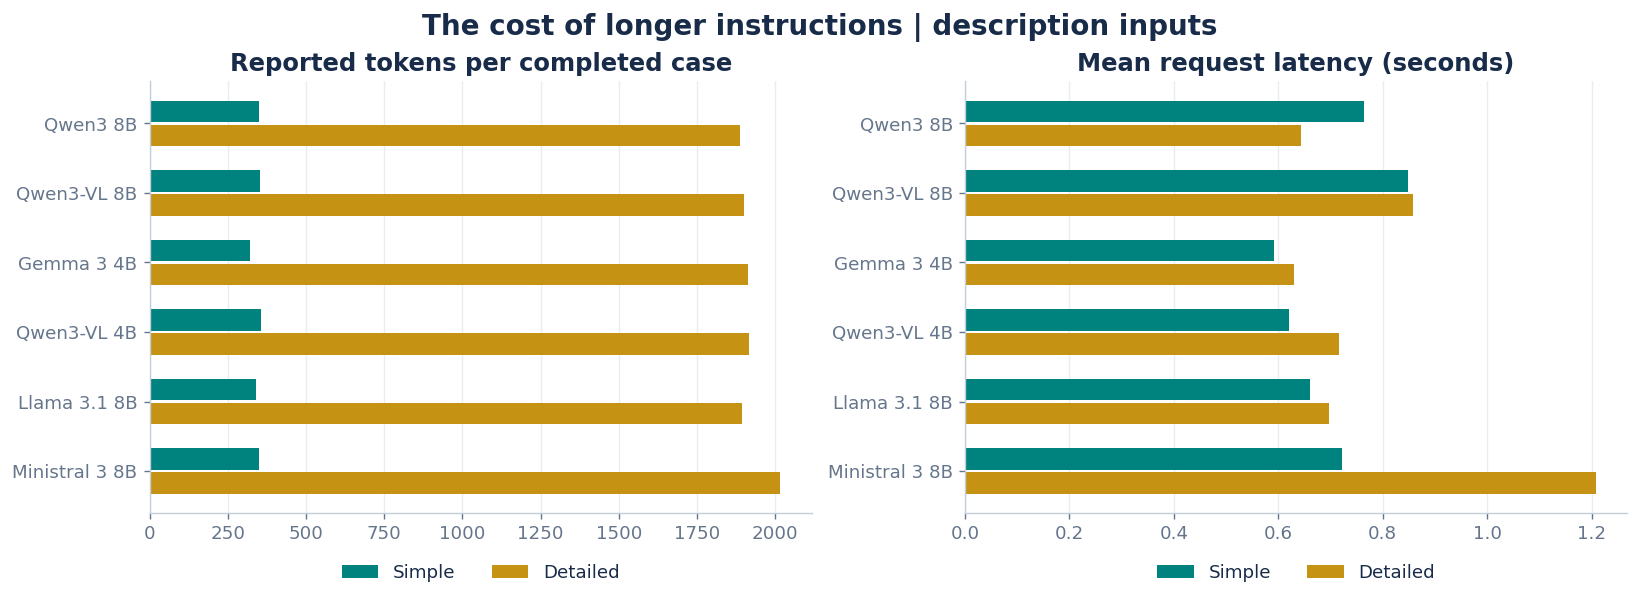

Model,Detailed tokens,Simple tokens,Detailed / simple
Qwen3 8B,1888.6,348.4,5.42×
Qwen3-VL 8B,1901.0,352.3,5.40×
Gemma 3 4B,1913.1,322.4,5.93×
Qwen3-VL 4B,1917.2,356.2,5.38×
Llama 3.1 8B,1892.8,340.1,5.57×
Ministral 3 8B,2016.2,350.7,5.75×


In [4]:
analysis.pretty_table(analysis.prompt_overview(DATA))
display(Code(json.dumps(DATA["plan"]["schema"], indent=2), language="json"))
analysis.prompt_cost_chart(DATA)
prompt_tokens = PERFORMANCE.query("modality == 'text'").pivot(index="model_name", columns="variant", values="total_tokens").reindex(analysis.MODEL_NAMES.values()).reset_index()
prompt_tokens["Detailed / simple"] = prompt_tokens["detailed"] / prompt_tokens["simple"]
analysis.pretty_table(prompt_tokens.rename(columns={"model_name":"Model", "simple":"Simple tokens", "detailed":"Detailed tokens"}),
    {"Simple tokens":"{:.1f}", "Detailed tokens":"{:.1f}", "Detailed / simple":"{:.2f}×"})

The length table counts the rendered system prompt, including categories and detailed definitions. Reported inference tokens additionally include the case payload, schema/template overhead, and images when present. Token accounting is model-specific and is not a common tokenizer measure across architectures. The chart holds the modality at description inputs to isolate prompt overhead. Request latency reflects observed cache and load behavior.

## 4 · How the scores are defined

The two tasks are evaluated separately:

| Measure | Definition and interpretation |
|---|---|
| Misroute precision | `TP / (TP + FP)` against held-out weak misroute labels |
| Misroute recall | `TP / (TP + FN)`; an abstention on a positive is an unflagged positive |
| Misroute F1 | `2 TP / (2 TP + FP + FN)` |
| False positives | Requests flagged as misroutes whose weak labels are negative |
| Flag accuracy | `(TP + TN) / labeled N`; all abstentions count as incorrect |
| Category agreement | Predicted category matches original/current exported category, using reference aliases |
| Abstention | JSON `null`, measured separately for the flag and the category |
| Inference resources | Actual request wall time, provider-reported tokens, and all-attempt totals |

**There are no independently adjudicated category or misroute labels in this cohort.** Verified accuracy is unavailable, never substituted with historical agreement. F1 alone does not penalize abstention on weak-negative cases, so coverage, abstentions, and false positives are reported alongside it.

## 5 · Standardized model comparison

This comparison holds the **simple prompt and description inputs constant** across all six models. It avoids giving each model a different configuration in the main architecture comparison.

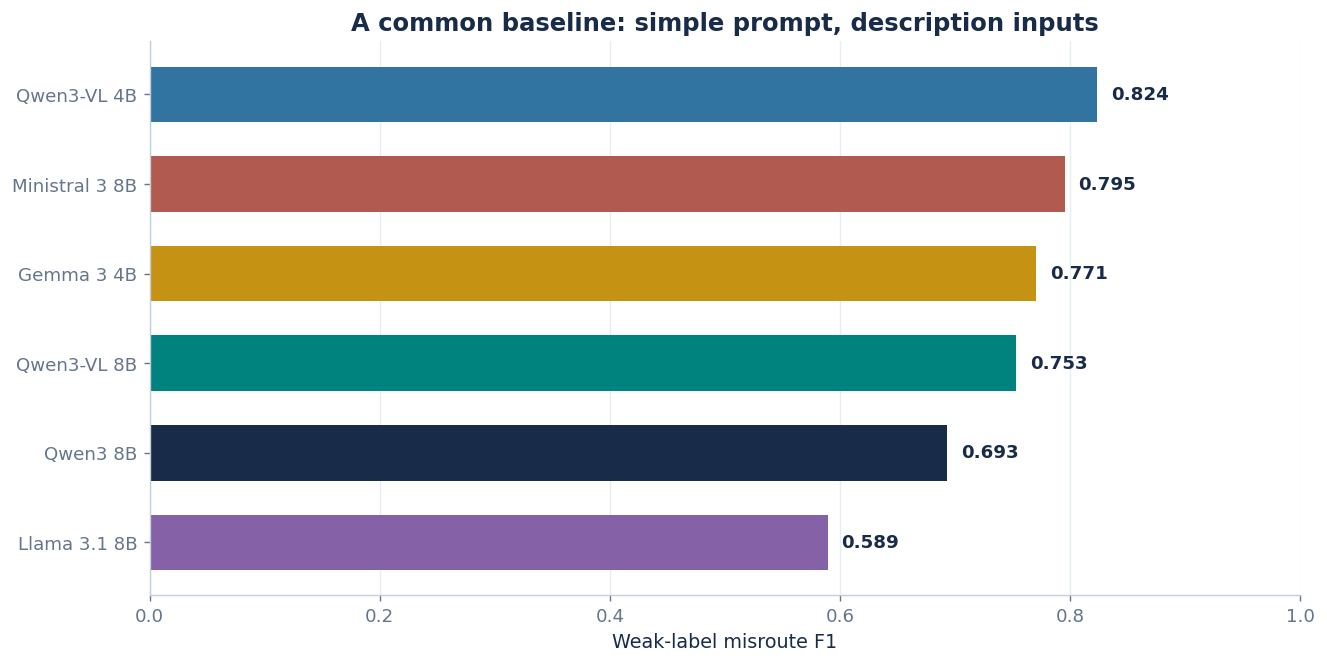

Model,Inputs,Prompt,N,Precision,Recall,F1,False positives,Flag abstention,Original agreement,Current agreement,Latency (s),Reported tokens
Qwen3-VL 4B,Description,Simple,100,0.764,0.894,0.824,13,0.0%,0.520000,71.0%,0.621,356
Ministral 3 8B,Description,Simple,100,0.854,0.745,0.795,6,0.0%,0.510000,74.0%,0.721,351
Gemma 3 4B,Description,Simple,100,0.677,0.894,0.771,20,0.0%,0.540000,71.0%,0.592,322
Qwen3-VL 8B,Description,Simple,100,0.842,0.681,0.753,6,0.0%,0.600000,72.0%,0.849,352
Qwen3 8B,Description,Simple,100,0.929,0.553,0.693,2,0.0%,0.610000,72.0%,0.765,348
Llama 3.1 8B,Description,Simple,100,0.508,0.702,0.589,32,14.0%,0.450000,66.0%,0.661,340


In [5]:
common = analysis.common_text_ranking(DATA)
analysis.pretty_table(analysis.metric_table(common), {
    "Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}", "Flag abstention": "{:.1%}",
    "Current agreement": "{:.1%}", "Latency (s)": "{:.3f}", "Reported tokens": "{:.0f}"
})

## 6 · Full matrix and best observed configurations

The heatmap shows every supported model/prompt/input combination. Gray cells are unsupported, not zero scores. A dagger marks a configuration with fewer than 100 valid outputs; its displayed score uses completed cases only and is excluded from configuration selection.

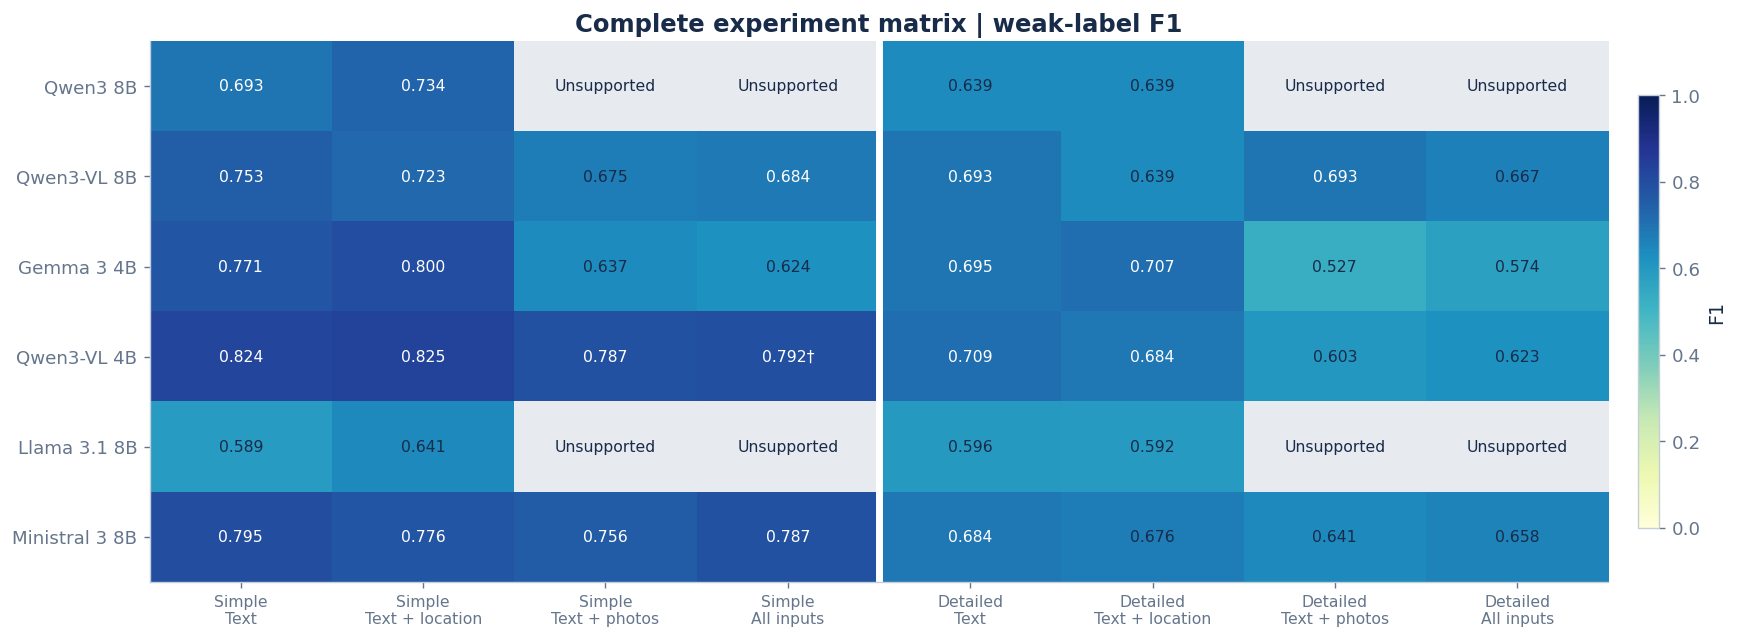

Model,Inputs,Prompt,N,Precision,Recall,F1,False positives,Flag abstention,Original agreement,Current agreement,Latency (s),Reported tokens
Qwen3-VL 4B,Description + location,Simple,100,0.800,0.851,0.825,10,0.0%,0.520000,72.0%,0.543,389
Gemma 3 4B,Description + location,Simple,100,0.724,0.894,0.800,16,0.0%,0.550000,71.0%,0.470,354
Ministral 3 8B,Description,Simple,100,0.854,0.745,0.795,6,0.0%,0.510000,74.0%,0.721,351
Qwen3-VL 8B,Description,Simple,100,0.842,0.681,0.753,6,0.0%,0.600000,72.0%,0.849,352
Qwen3 8B,Description + location,Simple,100,0.906,0.617,0.734,3,0.0%,0.580000,74.0%,0.630,380
Llama 3.1 8B,Description + location,Simple,100,0.589,0.702,0.641,23,28.0%,0.440000,64.0%,0.544,358


In [6]:
analysis.score_heatmap(DATA)
eligible = PERFORMANCE.query("completed == 100 and failed == 0")
best_per_model = eligible.sort_values(["weak_f1", "mean_latency_seconds"], ascending=[False, True]).drop_duplicates("model")
analysis.pretty_table(analysis.metric_table(best_per_model), {
    "Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}", "Flag abstention": "{:.1%}",
    "Current agreement": "{:.1%}", "Latency (s)": "{:.3f}", "Reported tokens": "{:.0f}"
})

These are **best observed development-set scores**, not validated generalization estimates. Selecting among many configurations on the same 100 cases can overstate future performance. The full tables retain precision/recall tradeoffs, sample sizes, and every partial result.

## 7 · Category recommendation and abstention

Agreement with the held-out current category is a useful historical consistency check, but current routing can itself be imperfect or reflect later information. Original agreement is descriptive, not a success target. A model can improve category agreement while detecting fewer weakly labeled misroutes.

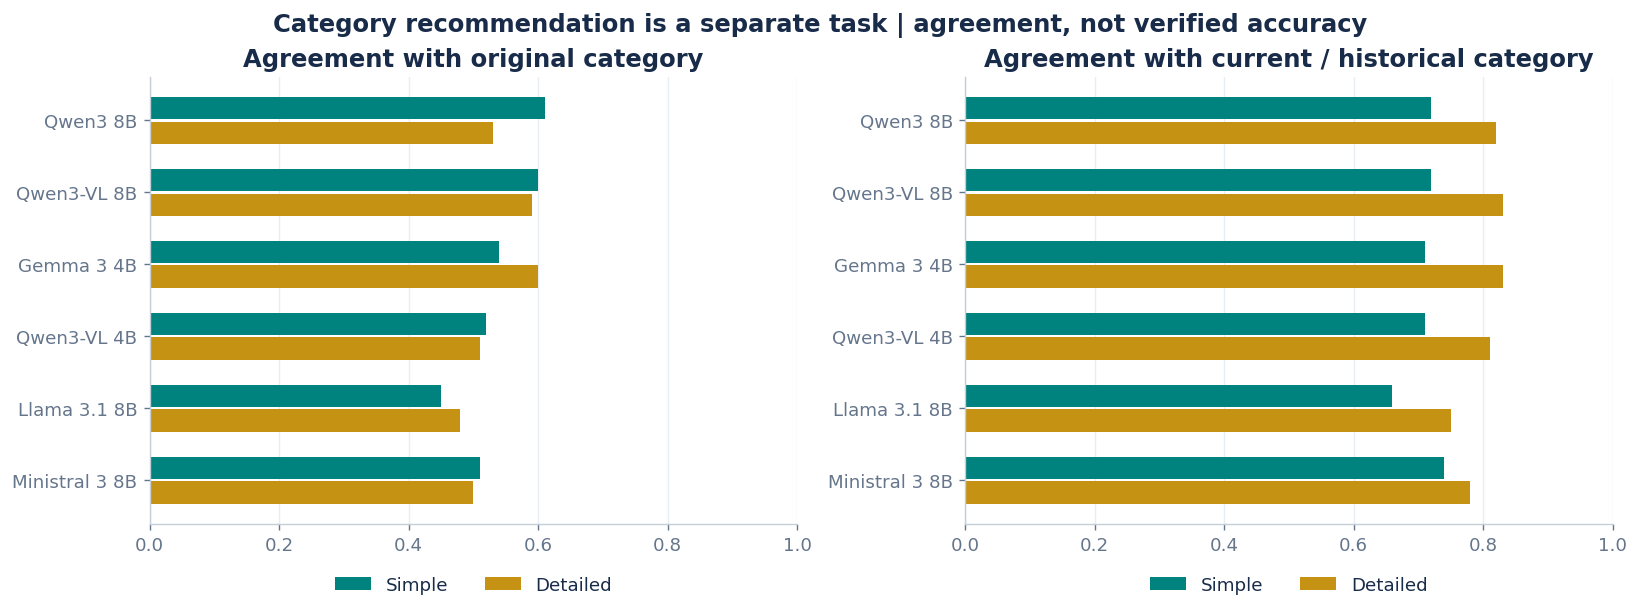

Model,Prompt,N,Flag abstention,Category abstention,Weak flag accuracy,False positives
Qwen3 8B,Simple,100,0.0%,0.0%,77.0%,2
Qwen3 8B,Detailed,100,0.0%,0.0%,74.0%,2
Qwen3-VL 8B,Simple,100,0.0%,0.0%,79.0%,6
Qwen3-VL 8B,Detailed,100,0.0%,0.0%,77.0%,2
Gemma 3 4B,Simple,100,0.0%,0.0%,75.0%,20
Gemma 3 4B,Detailed,100,4.0%,0.0%,69.0%,15
Qwen3-VL 4B,Simple,100,0.0%,0.0%,82.0%,13
Qwen3-VL 4B,Detailed,100,4.0%,0.0%,77.0%,4
Llama 3.1 8B,Simple,100,14.0%,0.0%,50.0%,32
Llama 3.1 8B,Detailed,100,10.0%,1.0%,58.0%,19


In [7]:
analysis.agreement_chart(DATA)
abstentions = PERFORMANCE.query("modality == 'text'")[["model_name", "prompt", "completed", "flag_abstention_rate", "category_abstention_rate", "weak_flag_accuracy", "weak_fp"]].rename(columns={
    "model_name":"Model", "prompt":"Prompt", "completed":"N", "flag_abstention_rate":"Flag abstention",
    "category_abstention_rate":"Category abstention", "weak_flag_accuracy":"Weak flag accuracy", "weak_fp":"False positives"})
analysis.pretty_table(abstentions, {"Flag abstention":"{:.1%}", "Category abstention":"{:.1%}", "Weak flag accuracy":"{:.1%}"})

The earlier detailed prompt did not explicitly define the negative (`false`) decision and often emitted null while describing a reasonable fit. The reused v2 prompt makes all three decisions explicit. Previously saved calibration probes show that clear-fit handling improved, but Qwen3-VL 8B still flagged a deliberately vague complaint. This is a remaining uncertainty-handling limitation. Those fixture probes are **not scored as dataset cases**, and no additional calibration experiments were introduced for the two new models.

## 8 · Paired ablations: location, photographs, and instructions

Each difference below compares **identical completed cases**, not separate samples. The photo effect is measured both without and with location, so the combined-input experiment does not conflate the two additions. Positive differences favor the added input; negative differences favor the baseline.

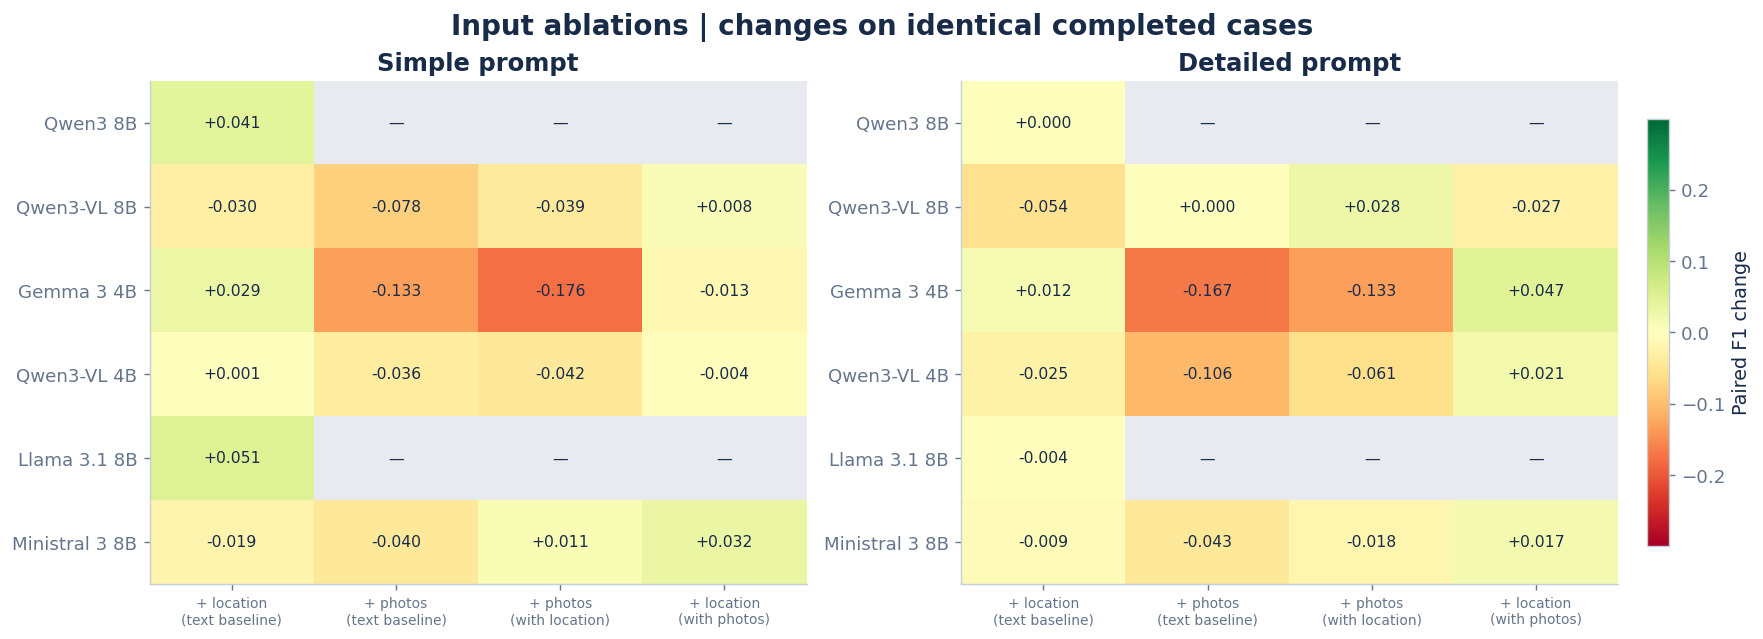

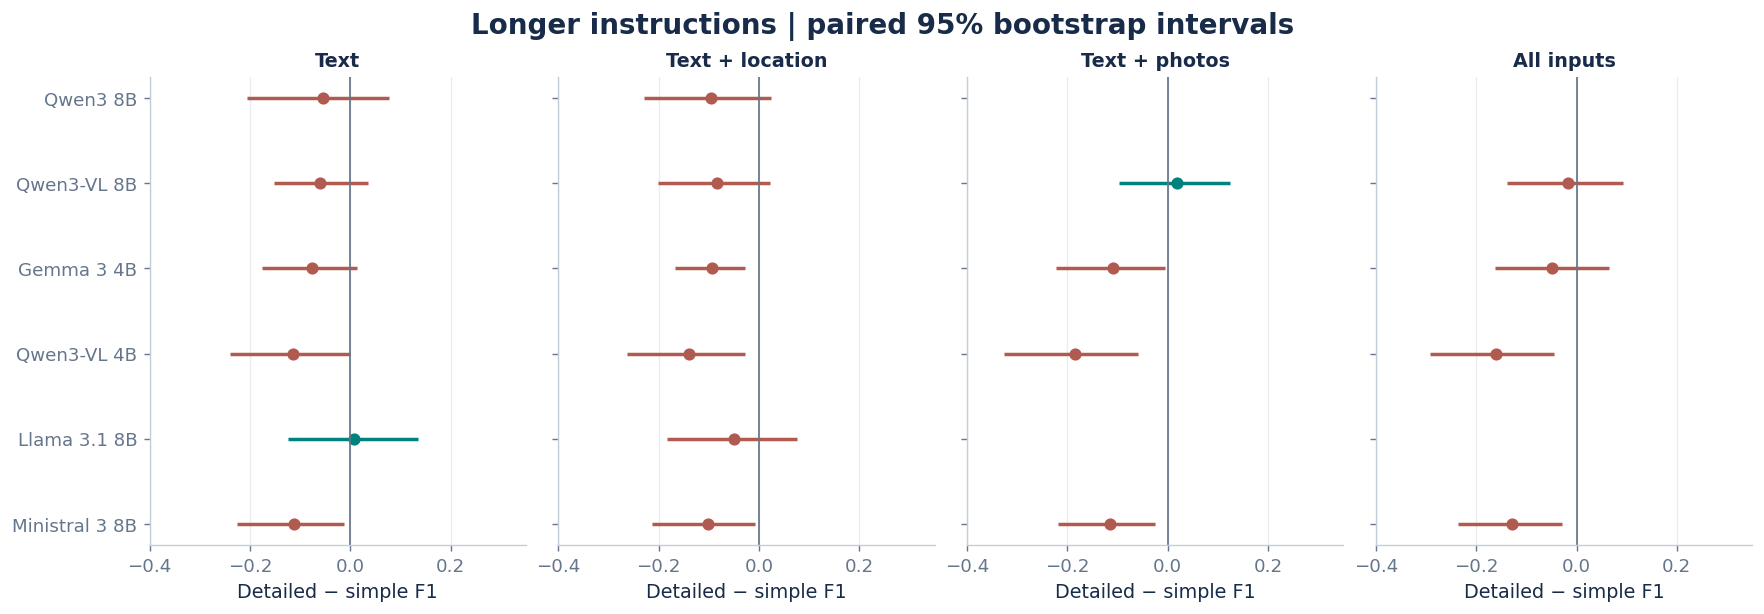

In [8]:
effects, photo_subset = analysis.ablations(DATA)
analysis.ablation_chart(DATA, effects)
paired_prompts = analysis.prompt_difference_chart(DATA)

Intervals are descriptive 95% paired case-bootstrap percentile intervals using 1,000 resamples. Both model/prompt predictions for a case are resampled together. Intervals are unadjusted for multiple comparisons; ranking uncertainty and weak-label bias remain.

**Photo-available subset.** To distinguish a genuine photo comparison from no-photo fallback, the table below restricts both sides to cases with linked images and compares description against description + photos. It uses the same cases on each side; it is an additional analysis of saved predictions, not an additional inference experiment.

In [9]:
analysis.pretty_table(photo_subset.rename(columns={"paired_n":"Paired N", "delta_f1":"Photo F1 change", "ci_low":"95% low", "ci_high":"95% high"}),
    {"Photo F1 change":"{:+.3f}", "95% low":"{:+.3f}", "95% high":"{:+.3f}"})

Model,Prompt,Paired N,Photo F1 change,95% low,95% high
Qwen3-VL 8B,Simple,85,-0.098,-0.244,+0.036
Qwen3-VL 8B,Detailed,85,+0.021,-0.086,+0.136
Gemma 3 4B,Simple,85,-0.157,-0.282,-0.057
Gemma 3 4B,Detailed,85,-0.174,-0.287,-0.064
Qwen3-VL 4B,Simple,85,-0.052,-0.142,+0.026
Qwen3-VL 4B,Detailed,85,-0.100,-0.242,+0.027
Ministral 3 8B,Simple,85,-0.049,-0.143,+0.044
Ministral 3 8B,Detailed,85,-0.021,-0.104,+0.073


## 9 · Resource use and practical tradeoffs

All models ran locally; **API charges are $0**. Hardware acquisition, power, cooling, and staff review are not measured and must not be interpreted as free. Reported tokens use each model's accounting. The latency measurements include HTTP/model processing and observed cold loads/cache effects, exclude queue waiting, and are descriptive of this machine and schedule—not production throughput estimates.

The audit below validates every saved request and response, including retries, before generating the all-attempt resource summary.

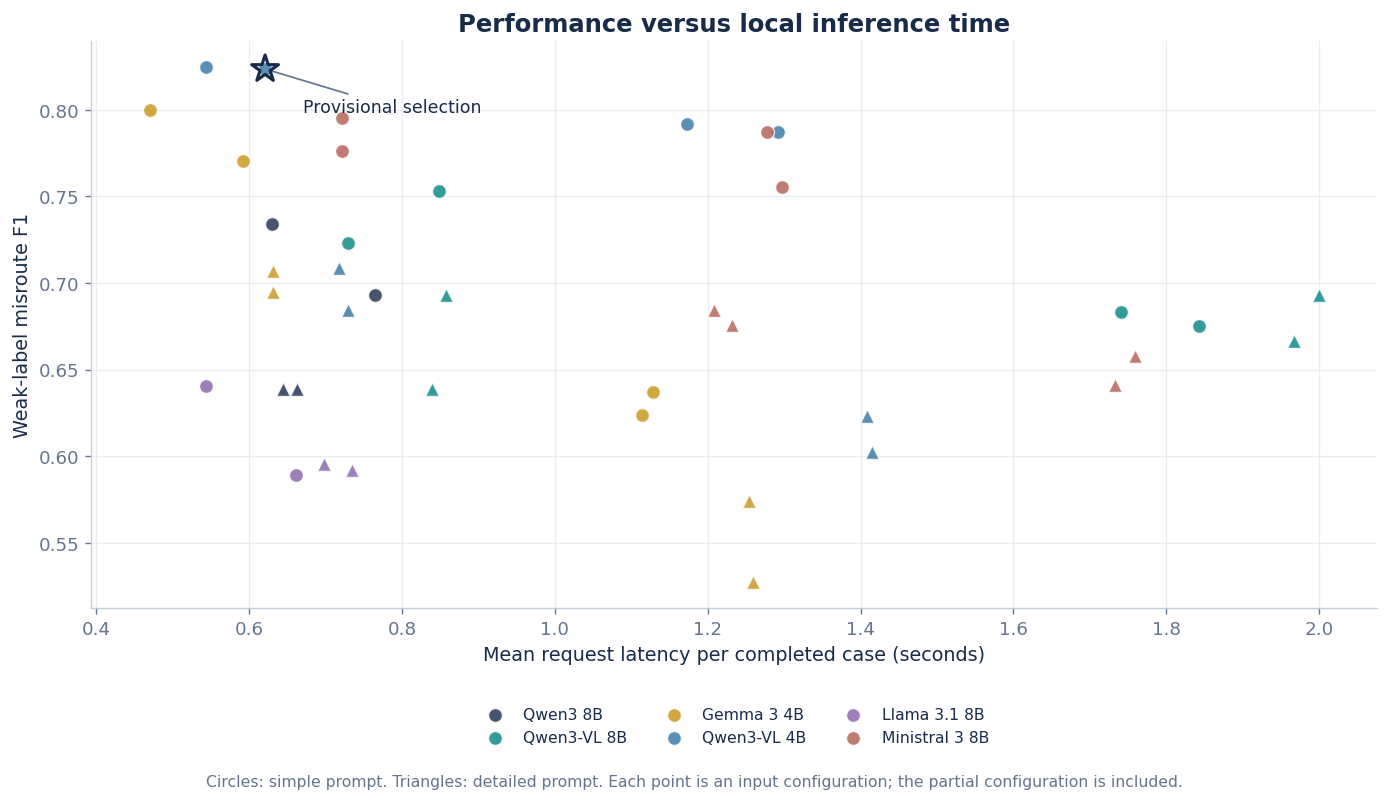

Model,Actual attempts,Request minutes,Reported input tokens,Reported output tokens,Model load seconds,Decode seconds
Qwen3 8B,400,4.50,430796,22993,16.10,232.97
Qwen3-VL 8B,800,18.04,1417524,59089,20.25,606.53
Gemma 3 4B,800,11.80,1013536,44704,16.55,374.85
Qwen3-VL 4B,802,13.38,1420228,69178,20.19,498.79
Llama 3.1 8B,400,4.40,425680,24869,13.63,229.42
Ministral 3 8B,800,16.58,1324168,65734,17.17,714.23


In [10]:
audit = analysis.audit_requests(DATA)
analysis.resource_chart(DATA)
resources = DATA["resources"].copy()
resources["Request minutes"] = resources.request_seconds / 60
resources["Reported input tokens"] = resources.input_tokens
resources["Reported output tokens"] = resources.output_tokens
resources["Model load seconds"] = resources.load_seconds
resources["Decode seconds"] = resources.decode_seconds
resource_table = resources[["model_name", "attempts", "Request minutes", "Reported input tokens", "Reported output tokens", "Model load seconds", "Decode seconds"]].rename(columns={"model_name":"Model", "attempts":"Actual attempts"})
analysis.pretty_table(resource_table, {"Request minutes":"{:.2f}", "Model load seconds":"{:.2f}", "Decode seconds":"{:.2f}"})
original_timing = analysis.read_json(BUNDLE / "provenance/existing_four/execution_summary.json")
new_timing = analysis.read_json(BUNDLE / "runtime/new_models_summary.json")
display(HTML(f"<p>Original four-model benchmark wall time: <b>{original_timing['wall_seconds']/60:.2f} minutes</b>. Two-model extension wall time: <b>{new_timing['wall_seconds']/60:.2f} minutes</b>. These exclude model downloads and later notebook/audit execution. Original post-run retries are included in all-attempt resource totals.</p>"))

## 10 · Key findings and provisional choice

In [11]:
analysis.findings(DATA, paired_prompts, effects)
selected = DATA["selected"]
selection = {"model":selected.model, "model_name":selected.model_name, "prompt":selected.variant,
    "modality":selected.modality, "weak_label_f1":float(selected.weak_f1),
    "weak_label_precision":float(selected.weak_precision), "weak_label_recall":float(selected.weak_recall),
    "mean_request_seconds":float(selected.mean_latency_seconds), "verified_accuracy_available":False,
    "selection_rule":"Fully completed configurations within 0.01 F1 of the highest observed score; then fewer modalities, simple prompt, fewer reported tokens. Post-hoc descriptive selection."}
(BUNDLE / "analysis/selected_configuration.json").write_text(json.dumps(selection, indent=2) + "\n", encoding="utf-8")

511

## 11 · Validation, failures, and reproducibility

The final package imports the original predictions and raw attempts into a new plan namespace. Origin tables retain the original experiment/attempt IDs and exact source-row hashes. The previous source checkpoint and reports remain unchanged. Only the two requested new models were executed. Completed predictions are not duplicated on resume; raw failures remain inspectable in SQLite.

In [12]:
checks = pd.DataFrame([
    {"Validation": "Metric values independently recomputed", "Result": str(audit["independent_metric_values_checked"])},
    {"Validation": "Actual model attempts inspected", "Result": str(audit["attempts_checked"])},
    {"Validation": "Case-owned image payloads verified", "Result": str(audit["case_owned_image_payloads_checked"])},
    {"Validation": "Imported prediction/status rows unchanged", "Result": str(audit["imported_prediction_rows_unchanged"])},
    {"Validation": "Imported raw attempts unchanged", "Result": str(audit["imported_attempt_rows_unchanged"])},
    {"Validation": "Original archived files unchanged", "Result": str(audit["prior_archive_files_unchanged"])},
    {"Validation": "Same 100 cases, prompts, and common schema", "Result": "Verified"},
    {"Validation": "Input allowlist / held-out scoring labels", "Result": "Verified"},
    {"Validation": "Paid API calls", "Result": str(audit["paid_api_calls"])},
])
analysis.pretty_table(checks)
failed = PERFORMANCE[PERFORMANCE.failed.gt(0)][["model_name", "input_configuration", "prompt", "completed", "failed"]].rename(columns={"model_name":"Model", "input_configuration":"Inputs", "prompt":"Prompt", "completed":"Valid N", "failed":"Failed N"})
if len(failed):
    display(HTML("<div class='caveat'><b>Incomplete coverage is retained:</b> the configurations below have failed model outputs. Their scores use completed cases only; paired analyses use the intersection, and selection excludes them.</div>"))
    analysis.pretty_table(failed)
else:
    display(HTML("<p>All supported configurations completed.</p>"))
errors = pd.DataFrame(audit["errors"])
if len(errors):
    grouped = errors.groupby(["model", "modality", "prompt", "error"], dropna=False).size().reset_index(name="Failed attempts")
    grouped["model"] = grouped["model"].map(analysis.MODEL_NAMES)
    grouped["modality"] = grouped["modality"].map(analysis.MODES)
    analysis.pretty_table(grouped.rename(columns={"model":"Model", "modality":"Inputs", "prompt":"Prompt", "error":"Recorded error"}))

Validation,Result
Metric values independently recomputed,3072
Actual model attempts inspected,4002
Case-owned image payloads verified,2146
Imported prediction/status rows unchanged,3200
Imported raw attempts unchanged,2802
Original archived files unchanged,52
"Same 100 cases, prompts, and common schema",Verified
Input allowlist / held-out scoring labels,Verified
Paid API calls,0


Model,Inputs,Prompt,Valid N,Failed N
Qwen3-VL 4B,Description + location + photos,Simple,99,1


Model,Inputs,Prompt,Recorded error,Failed attempts
Qwen3-VL 4B,Description + location + photos,simple,AdapterError: Truncated or incomplete response,3


## 12 · Limits of the evidence

- **Weak targets and source-model bias:** Historical routing and proxy misroute labels can be wrong. Earlier Qwen3 8B screening influenced label/cohort construction and may favor Qwen-family agreement. No verified accuracy is reported.
- **Development selection:** The frozen cohort is small and selected from a category-matched development collection. The class mix and performance may not generalize to citywide requests.
- **Selection on the evaluation cohort:** Configuration rankings and the one-percentage-point heuristic are exploratory. Independent adjudication and a separate test cohort are needed to validate a final deployment choice.
- **Photograph timing:** Parent-case linkage is checked, but image upload times and before/after roles are unavailable. Photo results do not establish performance with exclusively initial-report images.
- **Text/location timing:** Exported descriptions and coordinates are not verified immutable submission snapshots; descriptions may contain dispatch/work-order annotations. Blocking downstream columns does not establish that the remaining text is free of later information.
- **Geographic information:** Raw coordinates alone provide limited semantic location context. These runs do not test a GIS-enriched system.
- **Abstention and failures:** Valid JSON does not guarantee correct reasoning. F1 can conceal abstentions on negative cases. Failed outputs and semantic uncertainty failures are retained and reported.
- **Compute comparability:** Quantization, provider tokenization, prompt caching, cold loads, runtime backend, and desktop load affect latency. Energy and total ownership cost were not measured; no cloud-model comparison was run.
- **Multiple comparisons:** Bootstrap intervals are descriptive, unadjusted, and do not remove weak-label bias. Small rank differences should not be treated as decisive.

## Appendix · Complete results and audit trail

The notebook contains no paid or local model calls. Re-executing it rebuilds its tables, figures, selected-configuration record, and validation report from the frozen checkpoint. The full machine-readable tables and exact prompts are included in the package.

In [13]:
full = analysis.metric_table(PERFORMANCE)
display(HTML("<details><summary>Show all 48 planned model / prompt / input configurations</summary>" + full.to_html(index=False, float_format=lambda x:f"{x:.3f}", na_rep="—") + "</details>"))
for variant, prompt in DATA["plan"]["prompts"].items():
    import html
    display(HTML(f"<details><summary>Exact {variant} prompt · {prompt['version']}</summary><pre style='white-space:pre-wrap'>{html.escape(prompt['system'])}</pre></details>"))
environment = analysis.read_json(BUNDLE / "reproducibility/environment.json")
display(HTML(f"<p><b>GPU:</b> {environment['gpu']}<br><b>Python:</b> {environment['python']}<br><b>Frozen plan SHA-256:</b> <code>{DATA['plan']['id']}</code></p>"))
display(HTML("<details><summary>Independent metric implementation</summary><pre>" + html.escape(inspect.getsource(analysis.independent_metrics)) + "</pre></details>"))
assert audit["audit_passed"] and audit["input_allowlist_and_common_schema_valid"]
assert PERFORMANCE.completed.sum() == len(DATA["records"])
assert PERFORMANCE.verified_flag_n.sum() == 0
print("Notebook validation complete: all displayed scores use saved real predictions; no inference or paid API calls were made.")

Model,Inputs,Prompt,N,Precision,Recall,F1,False positives,Flag abstention,Original agreement,Current agreement,Latency (s),Reported tokens
Qwen3 8B,Description,Simple,100,0.929,0.553,0.693,2,0.000,0.610,0.720,0.765,348.420
Qwen3 8B,Description,Detailed,100,0.920,0.489,0.639,2,0.000,0.530,0.820,0.644,1888.600
Qwen3 8B,Description + location,Simple,100,0.906,0.617,0.734,3,0.000,0.580,0.740,0.630,380.000
Qwen3 8B,Description + location,Detailed,100,0.920,0.489,0.639,2,0.000,0.530,0.810,0.662,1920.870
Qwen3 8B,Description + photos,Simple,0,—,—,—,0,—,—,—,—,—
Qwen3 8B,Description + photos,Detailed,0,—,—,—,0,—,—,—,—,—
Qwen3 8B,Description + location + photos,Simple,0,—,—,—,0,—,—,—,—,—
Qwen3 8B,Description + location + photos,Detailed,0,—,—,—,0,—,—,—,—,—
Qwen3-VL 8B,Description,Simple,100,0.842,0.681,0.753,6,0.000,0.600,0.720,0.849,352.290
Qwen3-VL 8B,Description,Detailed,100,0.929,0.553,0.693,2,0.000,0.590,0.830,0.858,1901.000


Notebook validation complete: all displayed scores use saved real predictions; no inference or paid API calls were made.


**Primary model references:** [Llama 3.1 8B](https://ollama.com/library/llama3.1:8b) · [Ministral 3 8B](https://ollama.com/library/ministral-3:8b) · [Qwen3 8B](https://ollama.com/library/qwen3:8b) · [Qwen3-VL 8B](https://ollama.com/library/qwen3-vl:8b-instruct-q4_K_M) · [Qwen3-VL 4B](https://ollama.com/library/qwen3-vl:4b-instruct-q4_K_M) · [Gemma 3 4B](https://ollama.com/library/gemma3:4b).

Model capability and runtime details in this notebook come from the pinned local Ollama fingerprints and recorded runtime metadata. The links identify the corresponding model distributions; they are not sources for benchmark scores.